In [8]:
import numpy as np
import matplotlib.pyplot as plt
import xobjects as xo
import xtrack as xt
import xpart as xp
import sys
import xplt
import scipy.constants as sc

sys.path.append('/mnt/c/muco/code')
from rcsparameters.geometry.geometry import Geometry, load_file
from rcsparameters.geometry.cell import Cell
from generate_fodo import fodo, plot_twiss, apert_1b_optics, apert_2b_optics, plot_path_diff
# from ramping_module import ramping
# from ramping_module import ramping
# from track_function import track
import json

plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

In [9]:
def make_line(rcs, n_turn_rcs , l_sxt, time, option, n_slice):
    # FODO_el, FODO_names, arc_el, arc_names=fodo(RCS=rcs, n_turn_rcs=n_turn_rcs , length_sxt=0.5, 
    #                                             time_frac=time, option=option, n_slice=n_slice)
    # tr=arc_el[2:]
    # tot_arc_el=tr[::-1]+arc_el
    # tr_name=arc_names[2:]
    # tot_arc_names=tr_name[::-1]+arc_names
    
    tot_arc_el, tot_arc_names=fodo(RCS=rcs, n_turn_rcs=n_turn_rcs , length_sxt=l_sxt, 
                                                time_frac=time, option=option, n_slice=n_slice)
    line_tot=xt.Line(elements=tot_arc_el*rcs.nb_arc, element_names=tot_arc_names*rcs.nb_arc)
    line_tot.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
    line_tot.build_tracker()
    survey=line_tot.survey()

    print(f"Survey closes ? X:{survey['X'][-1]:.2}, Y:{survey['Y'][-1]:.2}, Z:{survey['Z'][-1]:.2}, Th:{survey['theta'][-1]/np.pi/2:.7}")
    print(f"Total circumference survey {survey['s'][-1]}")
    return line_tot, survey

RCS1: Normal in SPS

In [10]:
RF_length_RCS1 = 974
RF_length_RCS2 = 2760
RF_length_RCS3 = 2850
l_cav = 1.2474

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_CERN_RCS1.txt
5.0


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 10 to 7
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)
/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 7 to 6
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


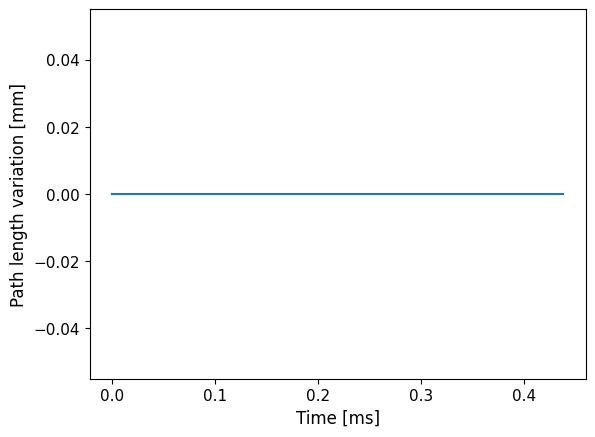

RESULT FOR RCS 1 NORMAL SPS
Number of arc 34
Nb of cells per arc 4
Cell length 43.66 m
Beta max 59.63 m   Dispersion max 0.87 m
MCF 0.00088
Max path length diff 0.0 mm
Relative path length diff [1e-6] 0.0


In [22]:
geo_rcs1 = '/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_CERN_RCS1.txt'
kw_geo_r1 = load_file(geo_rcs1)
CERN_RCS1 = {
        'n_sigma' : 6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta' : 1.5e-2, #Max dispersion in energy of the beam
        'emitt_n' : 25e-6, #Normalized emittance
        'n_cav' : 781, #Total number of cavity 
        'l_cav' : 1.2474, #Length of 1 cavity
        'mu' : np.pi/2, #Phase advance per cell
        'apert_min' : 30e-3, #Min aperture size (diam) to be taken for QP
        'dx' : 10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole' : 1, #Max field on QP pole
    }

rcs = Cell(file_input_geo = kw_geo_r1, file_input_opt = CERN_RCS1)
print(rcs.nb_cell_arc)
rcs.nb_cell_arc = 4

time = 0
n_slice = 0
option = 'var_ref'
l_sxt_rcs1 = 0.5
n_turn_rcs1 = 19

max_path_diff = plot_path_diff(rcs, n_turn_rcs1)
print('RESULT FOR RCS 1 NORMAL SPS')
print('Number of arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', round(rcs.cell_length,2),'m')
print('Beta max', round(rcs.beta_max,2), 'm   Dispersion max', round(rcs.disp_max,2),'m')
print('MCF', round(rcs.mcf,5))
print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
print('Relative path length diff [1e-6]', round(max_path_diff/rcs.circumference*1e6,2))

Nb arc 2
Nb cell per arc 27.0
RF insertion length 487.1097
Extra per quad: 10.226060445018957
Survey closes ? X:6.5e-12, Y:0.0, Z:3.1e-13, Th:-1.0
Total circumference survey 6912.6295453097955
Nb arc 4
Nb cell per arc 25.0
RF insertion length 243.55485
Extra per quad: 3.9401527673146237
Survey closes ? X:-8.8e-14, Y:0.0, Z:2e-13, Th:-1.0
Total circumference survey 6912.197197894356
Nb arc 8
Nb cell per arc 22.0
RF insertion length 121.777425
Extra per quad: 0.3553311112130272
Survey closes ? X:4.1e-11, Y:0.0, Z:2.3e-12, Th:-1.0
Total circumference survey 6912.070926096934
Nb arc 16
Nb cell per arc 11.0
RF insertion length 60.8887125
Extra per quad: 0.21077233502522744


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 22.0 to 13
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Survey closes ? X:4.2e-11, Y:0.0, Z:2e-12, Th:-1.0
Total circumference survey 6912.070926096923
Nb arc 24
Nb cell per arc 8.0
RF insertion length 40.592475
Geometry not possible, decreases nc from 8.0 to 7.0
Extra per quad: 0.2488414789598188


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 11.0 to 9
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Survey closes ? X:-5.7e-11, Y:0.0, Z:1.9e-12, Th:-1.0
Total circumference survey 6900.1326115575
Nb arc 32
Nb cell per arc 5.0
RF insertion length 30.44435625
Extra per quad: 0.34886550434590946


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 8.0 to 6
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Survey closes ? X:2.6e-11, Y:0.0, Z:-2.5e-12, Th:-1.0
Total circumference survey 6912.083970039423


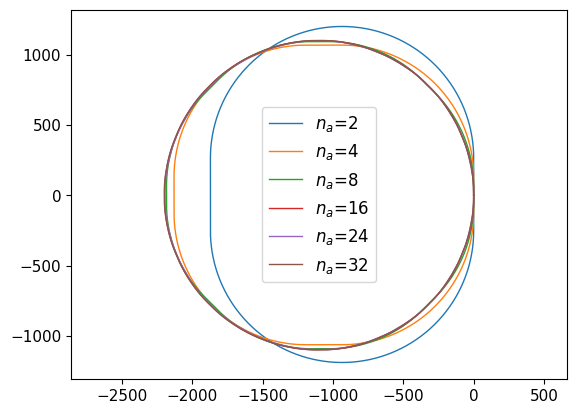

In [23]:
plt.figure()
for nb_arc in [2,4,8,16,24,32]:
    kw_geo_r1['nb_arc'] = nb_arc
    rcs = Cell(file_input_geo = kw_geo_r1, file_input_opt = CERN_RCS1)
    print('Nb arc', rcs.nb_arc)
    print('Nb cell per arc', rcs.nb_cell_arc)
    print('RF insertion length', rcs.insertion_length)
    line_tot, sv = make_line(rcs = rcs, n_turn_rcs = n_turn_rcs1 , l_sxt = l_sxt_rcs1, 
                            time = time, option = option, n_slice = n_slice)
    plt.plot(sv['X'], sv['Z'], label=f'$n_a$={nb_arc}', linewidth=1)
    # line_tot.to_json(f'line_nb_arc/rcs1_sps_{nb_arc}_arc.json')
plt.legend()
plt.axis('equal')
plt.show()


RCS2 : Normal in LHC

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_CERN_RCS2.txt


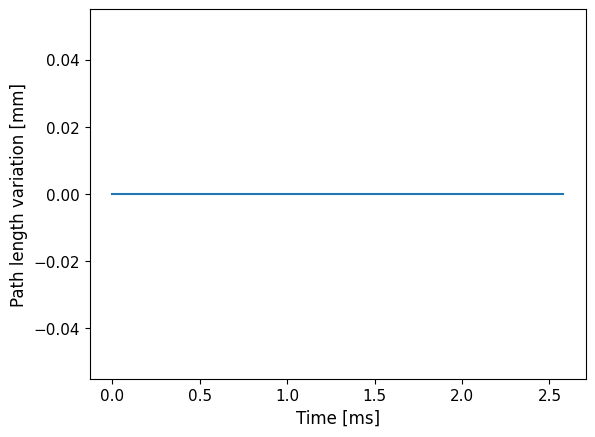

RESULT FOR RCS 2 NORMAL LHC
Number of arc 26
Nb of cells per arc 7.0
Cell length 131.31 m
Beta max 224.16 m   Dispersion max 3.07 m
MCF 0.00051
Max path length diff 0.0 mm
Relative path length diff [1e-6] 0.0


In [13]:
geo_rcs2 = '/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_CERN_RCS2.txt'
kw_geo_2 = load_file(geo_rcs2)
CERN_RCS2 = {
        'n_sigma' : 6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta': 5e-3, #Max dispersion in energy of the beam
        'emitt_n' : 25e-6, #Normalized emittance
        'n_cav' : 2213, #Total number of cavity : 700, 380, 540, 3000 
        'l_cav' : 1.2474, #Length of 1 cavity
        'mu' : np.pi/2, #Phase advance per cell
        'apert_min': 30e-3, #Min aperture size (diam) to be taken for QP
        'dx' : 10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole' : 1, #Max field on QP pole
    }
rcs = Cell(file_input_geo = kw_geo_2, file_input_opt = CERN_RCS2)
time = 0
n_slice = 0
option = 'var_ref'
l_sxt_rcs2 = 1
n_turn_rcs2 = 29

max_path_diff=plot_path_diff(rcs, n_turn_rcs2)
print('RESULT FOR RCS 2 NORMAL LHC')
print('Number of arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', round(rcs.cell_length,2),'m')
print('Beta max', round(rcs.beta_max,2), 'm   Dispersion max', round(rcs.disp_max,2),'m')
print('MCF', round(rcs.mcf,5))
print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
print('Relative path length diff [1e-6]', round(max_path_diff/rcs.circumference*1e6,2))

Nb arc 2
Nb cell per arc 29.0
Extra per quad: 35.27682331567052
Survey closes ? X:3e-11, Y:0.0, Z:-1.4e-11, Th:-1.0
Total circumference survey 26661.32838093748
insertion length 1380.2481000000007
Drift ins 1380.2481000000007
Nb arc 4
Nb cell per arc 28.0
Extra per quad: 16.292289813351587
Survey closes ? X:1.4e-12, Y:0.0, Z:-8.9e-12, Th:-1.0
Total circumference survey 26659.6371764475
insertion length 690.1240500000004
Drift ins 690.1240500000004
Nb arc 8
Nb cell per arc 27.0
Extra per quad: 5.818131703669443
Survey closes ? X:-2.2e-10, Y:0.0, Z:2.5e-12, Th:-1.0
Total circumference survey 26659.177913131338
insertion length 345.0620250000002
Drift ins 345.0620250000002
Nb arc 16
Nb cell per arc 14.0
Extra per quad: 5.101167372080813
Survey closes ? X:-1.1e-10, Y:0.0, Z:-1.2e-11, Th:-1.0
Total circumference survey 26659.16590407751
insertion length 172.5310125000001
Drift ins 172.5310125000001
Nb arc 24
Nb cell per arc 9.0
Extra per quad: 5.173524579396267
Survey closes ? X:-2.2e-10, Y

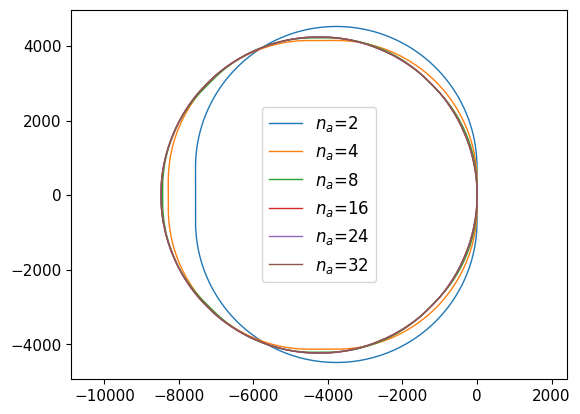

In [14]:
plt.figure()
for nb_arc in [2,4,8,16,24,32]:
    kw_geo_2['nb_arc'] = nb_arc
    rcs = Cell(file_input_geo = kw_geo_2, file_input_opt = CERN_RCS2)
    print('Nb arc', rcs.nb_arc)
    print('Nb cell per arc', rcs.nb_cell_arc)
    line_tot, sv = make_line(rcs = rcs, n_turn_rcs = n_turn_rcs2 , l_sxt = l_sxt_rcs2, 
                            time = time, option = option, n_slice = n_slice)
    print('insertion length', rcs.insertion_length)
    plt.plot(sv['X'], sv['Z'], label=f'$n_a$={nb_arc}', linewidth=1)
    # line_tot.to_json(f'line_nb_arc/rcs2_lhc_{nb_arc}_arc.json')
plt.legend()
plt.axis('equal')
plt.show()

RCS3 : Hybrid in LHC

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_CERN_RCS3.txt
1 bloc
geo


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 10 to 9
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


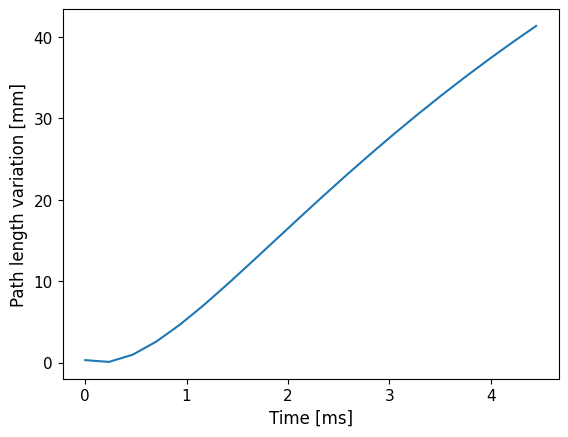

RESULT FOR RCS 3 Hybrid LHC
Number of arc 26
Nb of cells per arc 9.0
Cell length 101.75 m
Beta max 173.7 m   Dispersion max 1.85 m
MCF 0.00031
Max path length diff 41.3 mm
Relative path length diff [1e-6] 1.55


In [15]:
geo_rcs3 ='/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_CERN_RCS3.txt'

kw_geo_3 = load_file(geo_rcs3)
CERN_RCS3={
        'n_sigma' : 6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta' : 5e-3, #Max dispersion in energy of the beam
        'emitt_n' : 25e-6, #Normalized emittance
        'n_cav' : 2284, #Total number of cavity : 700, 380, 540, 3000 
        'l_cav' : 1.2474, #Length of 1 cavity
        'mu' : np.pi/2, #Phase advance per cell
        'apert_min' : 30e-3, #Min aperture size (diam) to be taken for QP
        'dx' : 10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole' : 1, #Max field on QP pole
    }

rcs = Cell(file_input_geo = kw_geo_3, file_input_opt = CERN_RCS3)

time = 0
n_slice = 0
option = 'var_ref'
l_sxt_rcs3 = 1
n_turn_rcs3 = 50

max_path_diff=plot_path_diff(rcs, n_turn_rcs3)
# rcs.plot_traj()
print('RESULT FOR RCS 3 Hybrid LHC')
print('Number of arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', round(rcs.cell_length,2),'m')
print('Beta max', round(rcs.beta_max,2), 'm   Dispersion max', round(rcs.disp_max,2),'m')
print('MCF', round(rcs.mcf,5))
print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
print('Relative path length diff [1e-6]', round(max_path_diff/rcs.circumference*1e6,2))

1 bloc
geo
Nb arc 2
Nb cell per arc 29.0
Extra per quad: 26.397051468249252
Survey closes ? X:-2e-11, Y:0.0, Z:5.5e-12, Th:-1.0
Total circumference survey 26659.995455918437
insertion length 1424.5308000000005
1 bloc
geo
Nb arc 4
Nb cell per arc 28.0
Extra per quad: 10.423483459006219
Survey closes ? X:7.6e-11, Y:0.0, Z:-5.9e-12, Th:-1.0
Total circumference survey 26659.29247359675
insertion length 712.2654000000002
1 bloc
geo
Nb arc 8
Nb cell per arc 27.0
Extra per quad: 0.7832893330465486
Survey closes ? X:-3.6e-11, Y:0.0, Z:-1e-12, Th:-1.0
Total circumference survey 26659.091836417727
insertion length 356.1327000000001
1 bloc
geo
Nb arc 16
Nb cell per arc 14.0
Extra per quad: 0.09290318127966408
Survey closes ? X:-3e-10, Y:0.0, Z:-1.1e-11, Th:-1.0
Total circumference survey 26659.086337996185
insertion length 178.06635000000006
1 bloc
geo
Nb arc 24
Nb cell per arc 9.0
Extra per quad: 0.20573688466228007
Survey closes ? X:-3.7e-11, Y:0.0, Z:-1.7e-12, Th:-1.0
Total circumference surve

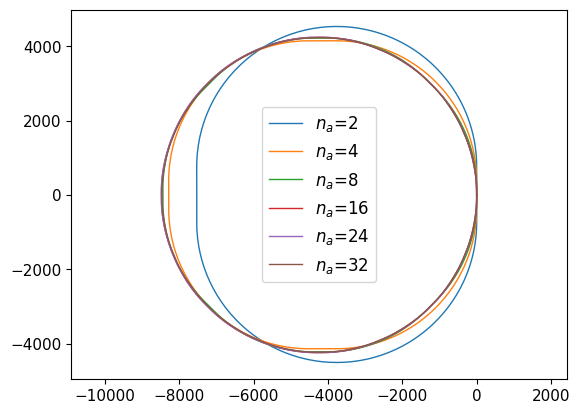

In [21]:
plt.figure()
for nb_arc in [2,4,8,16,24,32]:
    kw_geo_3['nb_arc'] = nb_arc
    rcs = Cell(file_input_geo = kw_geo_3, file_input_opt = CERN_RCS3)
    print('Nb arc', rcs.nb_arc)
    print('Nb cell per arc', rcs.nb_cell_arc)
    line_tot, sv = make_line(rcs = rcs, n_turn_rcs = n_turn_rcs3 , l_sxt = l_sxt_rcs3, 
                            time = time, option = option, n_slice = n_slice)
    print('insertion length', rcs.insertion_length)
    plt.plot(sv['X'], sv['Z'], label=f'$n_a$={nb_arc}', linewidth=1)
    line_tot.to_json(f'line_nb_arc/rcs3_lhc_{nb_arc}_arc.json')
plt.legend()
plt.axis('equal')
plt.show()